In [1]:
# Imports
import polars as pl
pl.Config.set_fmt_str_lengths(100)
import numpy as np
import seaborn as sns
import pandas as pd
from joblib import Parallel, delayed

import matplotlib.pylab as plt
from conversions import get_file_without_path
import glob
import os
import pickle

from sklearn.feature_selection import mutual_info_regression
from scipy import signal
from scipy import stats
import random
from scipy.stats import spearmanr
import pingouin

import pandas as pd
import numpy as np
import mne
from mne.stats import permutation_cluster_test
import matplotlib.pyplot as plt


# Visualisation and preprocessing

In [4]:
hr_data_file_name = "../../data/hr/hr_ws_6_with_filtering_June_2026.csv"

In [6]:
#Preprocessing dataset and exporting
import polars as pl
import polars.selectors as cs

output_path = "../../data/hr/hr_ws_6_with_filtering_June_2026_preprocessed.csv"

def main():
    print("Loading raw HR data...")
    all_data_df = pl.read_csv(hr_data_file_name)

    # 1. Aggregate duplicate timestamps (Your original grouping logic)
    print("Aggregating duplicate timestamps...")
    ts_df = (
            all_data_df.group_by([
        "sid", "dyad", "user_id", "other_id", 
        "participant_condition", "other_condition", 
        "file_name", "manipulated", "analysis", "time"
        ]).agg(cs.numeric().mean())
        .with_columns(
            pl.col("analysis")             # So we can add the method column
            .str.split("_")                # Split by underscore into a list
            .list.slice(0, 2)              # Grab the first two elements (offset=0, length=2)
            .list.join("_")                # Join them back together with an underscore
            .alias("method")               #Rename this method
        )
        .sort(["sid", "dyad", "analysis", "user_id", "time"])
    )

    # 2. Apply Interpolation and Smoothing over the grouped contexts
    print("Applying linear interpolation and moving average...")
    group_cols = ["sid", "dyad", "user_id", "method", "analysis"]
    
    # Adjust window_size depending on your sampling rate
    # (e.g., 3 means it averages the current row with the row before and after it)
    ma_window = 3 

    processed_df = ts_df.with_columns(
        pl.col("bpmES")
        .interpolate()                                    # 1. Linear interpolation for missing gaps
        .fill_null(strategy="backward")                   # 2. Catch any NaNs at the absolute beginning
        .fill_null(strategy="forward")                    # 3. Catch any NaNs at the absolute end
        .rolling_mean(window_size=ma_window, center=True) # 4. Apply centered smoothing
        .over(group_cols)                                 # Apply 1-4 independently per time series
    )

    
    # Save the globally preprocessed dataset
    processed_df.write_csv(output_path)
    print(f"[SUCCESS] Preprocessed data saved to {output_path}")

if __name__ == "__main__":
    main()

Loading raw HR data...
Aggregating duplicate timestamps...
Applying linear interpolation and moving average...
[SUCCESS] Preprocessed data saved to ../../data/hr/hr_ws_6_with_filtering_June_2026_preprocessed.csv


In [8]:
#Plot preprocessed time series

import polars as pl
import matplotlib.pyplot as plt
import random
import os

# Create output directory
os.makedirs("plots/individual_ts_preprocessed", exist_ok=True)

print("Loading data for visualization...")
df = pl.read_csv(output_path)

# Define the columns that uniquely identify a single time series
group_cols = ["sid", "dyad", "user_id", "analysis"]

# Extract unique combinations of these columns
unique_series = df.select(group_cols).unique().to_dicts()

# Randomly sample 10 series
random.seed(42) # For reproducibility
sampled_series = random.sample(unique_series, min(10, len(unique_series)))

print(f"Plotting {len(sampled_series)} randomly selected time series...")

for i, keys in enumerate(sampled_series):
    # Dynamically build the filter condition for this specific series
    condition = pl.lit(True)
    for col, val in keys.items():
        condition = condition & (pl.col(col) == val)
    
    # Filter and sort chronologically
    series_df = df.filter(condition).sort("time")
    
    # Plotting
    plt.figure(figsize=(12, 5))
    plt.plot(series_df["time"], series_df["bpmES"], label="Raw bpmES", color="#1f77b4", linewidth=1.5)
    
    plt.title(f"Sample {i+1} | SID: {keys['sid']} | Dyad: {keys['dyad']} | User: {keys['user_id']}")
    plt.xlabel("Time")
    plt.ylabel("Heart Rate (bpmES)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    
    # Save file
    safe_name = f"{keys['sid']}_{keys['dyad']}_{keys['user_id']}_{keys['analysis']}.png"
    plt.savefig(f"plots/individual_ts_preprocessed/{safe_name}")
    plt.close()

print("Visualization complete. Check the 'plots/individual_ts_preprocessed/' folder.")

Loading data for visualization...
Plotting 10 randomly selected time series...
Visualization complete. Check the 'plots/individual_ts_preprocessed/' folder.


# Analysis

In [9]:
#Choose the one you want
all_data_df = pl.read_csv("../../data/hr/hr_ws_6_with_filtering_June_2026_preprocessed.csv")


In [10]:
#all_data_df
np.unique(all_data_df["method"])

array(['HR_CNN', 'MTTS_CAN', 'cpu_GREEN', 'cpu_ICA', 'cpu_LGI',
       'cpu_OMIT', 'cpu_PBV', 'cpu_PCA', 'cupy_CHROM', 'cupy_POS'],
      dtype='<U10')

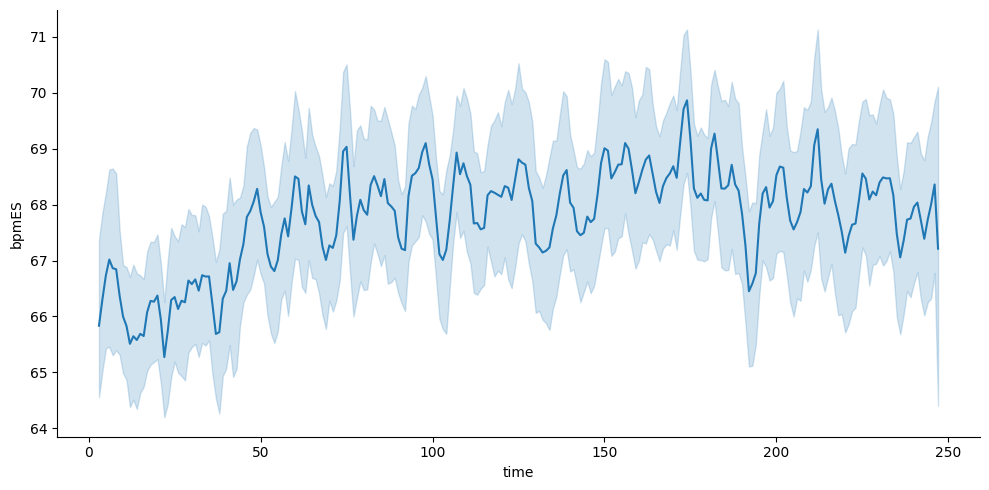

In [11]:
df_analysis = all_data_df.group_by(["time", "user_id"]).mean()

sns.relplot(x="time", y="bpmES", kind="line", data=df_analysis.to_pandas(), aspect=2)

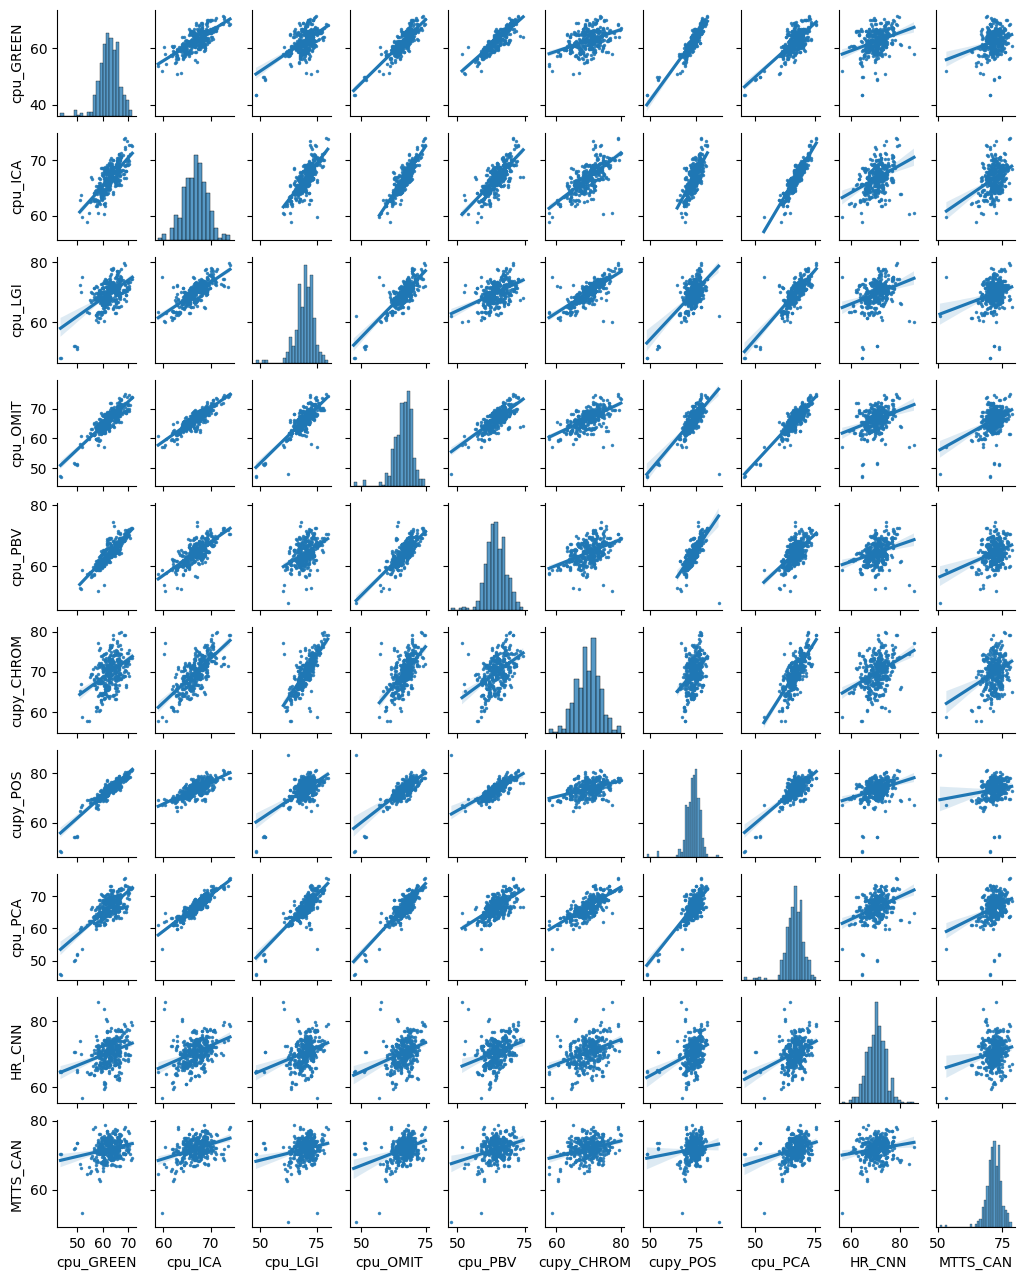

In [13]:
df_analysis = all_data_df.group_by(["dyad", "user_id", "manipulated", "method"]).mean().to_pandas()
df_analysis = df_analysis.pivot(index =["dyad", "user_id", "manipulated"] , columns="method", values="bpmES").reset_index()
df_analysis = df_analysis[["cpu_GREEN", "cpu_ICA", "cpu_LGI", "cpu_OMIT", "cpu_PBV", "cupy_CHROM", "cupy_POS", "cpu_PCA", "HR_CNN", "MTTS_CAN"]]

sns.pairplot(df_analysis, kind="reg", aspect=0.8, height=1.3, plot_kws={'scatter_kws': {'s': 2.2}})

plt.savefig("plots/paired_hr.pdf")

# Cross-Correlation Analysis

In [14]:
# Initialize the dataframes with the correct schema if they are not initialized
df_lags_schema = {
    "lag": pl.Int64,
    "corr": pl.Float64,
    "dyad": pl.Utf8,
    "source_feature": pl.Utf8,
    "target_feature": pl.Utf8,
    "participant_manipulated": pl.Boolean,
    "other_manipulated": pl.Boolean,
    "other_id": pl.Utf8,
    "sid": pl.Utf8,
    "user_id": pl.Utf8,
    "window": pl.Int64,
    "start": pl.Int64,
    "start_time": pl.Int64,
    "real_dyad": pl.Boolean,
    "repetition_nb": pl.Int64,
    "analysis" : pl.Utf8
}

mi_df_schema = {
    "source_feature": pl.Utf8,
    "target_feature": pl.Utf8,
    "other_id": pl.Utf8,
    "user_id": pl.Utf8,
    "participant_manipulated": pl.Boolean,
    "other_manipulated": pl.Boolean,
    "dyad": pl.Utf8,
    "sid": pl.Utf8,
    "mi": pl.Float64,
    "max_corr": pl.Float64,
    "mean_corr": pl.Float64,
    "window": pl.Int64,
    "start": pl.Int64,
    "start_time": pl.Int64,
    "real_dyad": pl.Boolean,
    "repetition_nb": pl.Int64,
    "analysis" : pl.Utf8
}

## Computig synchrony

In [15]:
all_data_df = pl.read_csv("../../data/hr/hr_ws_6_with_filtering_June_2026_preprocessed.csv")

In [16]:
#Compute synchrony
!python compute_synchrony_parallel.py -u pa121

Loading Data into Main Process...
Building fast lookup dictionary...
Data Indexed. Streaming tasks lazily to 32 cores...
[SUCCESS!] Saved CSVs: mkprolific_participant_real_22 p2p6 Real: True
[SUCCESS!] Saved CSVs: mkreal_meeting_experiment_prolific6 p1p8 Real: True
[SUCCESS!] Saved CSVs: mkprolific_participant_real_22 p4p6 Real: True
[SUCCESS!] Saved CSVs: mkprolific_participant_real_22 p4p6 Real: True
[SUCCESS!] Saved CSVs: mkreal_meeting_experiment_prolific4 p1p7 Real: True
[SUCCESS!] Saved CSVs: mkprolific_participant_real_22 p4p6 Real: True
[SUCCESS!] Saved CSVs: mkprolific_participant_real_21 p1p5 Real: True
[SUCCESS!] Saved CSVs: mkprolific_participant_real_32 p4p8 Real: True
[SUCCESS!] Saved CSVs: mkprolific_participant_real_32 p4p7 Real: True
[SUCCESS!] Saved CSVs: mkreal_meeting_experiment_prolific6 p3p5 Real: True
[SUCCESS!] Saved CSVs: mkreal_meeting_experiment_prolific6 p2p8 Real: True
[SUCCESS!] Saved CSVs: mkprolific_participant_real_32 p4p5 Real: True
[SUCCESS!] Saved CS

In [17]:
for data_folder in glob.glob("../../data/hr/*PREPRO*"):
    print( "---- ")
    print(data_folder)
    print("Number of files  in this analysis: " + str(len(glob.glob(data_folder+"/*df_lags.csv"))))

---- 
../../data/hr/filtered_data_synchrony_new_parallel_PREPRO_repetition_2_lag_20_overlap_1_wl_45_fill_limit30
Number of files  in this analysis: 24440


# Plotting - Real vs Fake - Only good pyVHR models

In [ ]:
holistic= True
if holistic:
    data_folder = "filtered_data_synchrony_new_parallel_PREPRO_repetition_2_lag_20_overlap_1_wl_45_fill_limit30"
    
    methods_to_keep = ["cupy_POS_holistic_median"       
          ,"cupy_CHROM_holistic_median"
          ,"cpu_LGI_holistic_median"
          ,"cpu_SSR_holistic_median"
          ,"cpu_OMIT_holistic_median"           
          , "cpu_PCA_holistic_median"    
          ,"cpu_ICA_holistic_median"
          ,"cpu_PBV_holistic_median"
    ]
else:
    data_folder = "filtered_data_synchrony_new_parallel_PREPRO_repetition_2_lag_20_overlap_1_wl_45_fill_limit30"
    methods_to_keep = ["cupy_POS_patches_clustering"       
          ,"cupy_CHROM_patches_clustering"
          ,"cpu_LGI_patches_clustering"
          ,"cpu_SSR_patches_clustering"
          ,"cpu_OMIT_patches_clustering"           
          ,"cpu_LGI_patches_clustering"
          ,"cupy_POS_patches_clustering"
          , "cpu_OMIT_patches_clustering"       
          , "cpu_PCA_patches_clustering"    
          ,"cpu_ICA_patches_clustering"
          ,"cpu_PBV_patches_clustering"
    ]


def fisher_mean(r_values):
    # Clip to avoid infinity if any values theoretically hit exactly 1.0 or -1.0
    r_clipped = np.clip(r_values, -0.9999, 0.9999)
    
    # arctanh is the Fisher z-transform, tanh is the inverse
    return np.tanh(np.mean(np.arctanh(r_clipped)))

In [21]:
# Optimal RAM handling
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
import glob

file_list = glob.glob(f"../../data/hr/{data_folder}/*df_lags.csv")

print(f"Found {len(file_list)} files. Processing in batches...")

agg_dfs = []
batch_size = 4000 # Adjust this up or down depending on your RAM/Speed sweet spot

# 1. Process files in fast, multi-threaded batches to optimise RAM
for i in range(0, len(file_list), batch_size):
    batch_files = file_list[i : i + batch_size]
    
    # scan_csv accepts a list of files and parallelizes the read!
    df_batch = (
        pl.scan_csv(batch_files, schema_overrides=df_lags_schema)
        .with_columns([
            pl.col(c).cast(d) for c, d in df_lags_schema.items()
        ])
        .filter(pl.col("analysis").is_in(methods_to_keep))
        # Updated grouping columns
        .group_by(["sid", "user_id", "real_dyad", "lag"])
        .agg(
            pl.col("corr") # Select Corr
            .clip(-0.9999, 0.9999) #Clip to be able to perform Fishcher Z transform
            .arctanh() #Fischer Z transform
            .mean() #Compute mean
            .alias("z_corr_batch")
            , pl.len().alias("n_rows") # Count rows for the weighted average
        )
        .collect(engine="streaming") 
    )
    agg_dfs.append(df_batch)
    print(f"Processed {min(i + batch_size, len(file_list))} / {len(file_list)} files...")

# 2. Combine the batched results and do one final reduction
print("Combining batches...")
final_pl = (
    pl.concat(agg_dfs)
    # Match the updated grouping columns from Step 1
    .group_by(["sid", "user_id", "real_dyad", "lag"])
    .agg(
        # Calculate the true weighted average
        (
            (pl.col("z_corr_batch") * pl.col("n_rows")).sum() / pl.col("n_rows").sum()
        ).alias("z_corr_final") 
    )
    .with_columns(
        # Inverse Fisher transform: convert the final z-score back to an r-value
        corr_mean = pl.col("z_corr_final").tanh()
    )
)

df_analysis_pd = final_pl.to_pandas()

print(f"Final Pandas Shape: {df_analysis_pd.shape}")


Found 24440 files. Processing in batches...
Processed 4000 / 24440 files...
Processed 8000 / 24440 files...
Processed 12000 / 24440 files...
Processed 16000 / 24440 files...
Processed 20000 / 24440 files...
Processed 24000 / 24440 files...
Processed 24440 / 24440 files...
Combining batches...
Final Pandas Shape: (4640, 6)


Bootstrapping CIs and plotting...


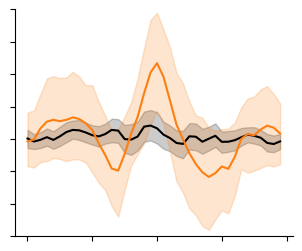

In [23]:
# 3. Plotting
print("Bootstrapping CIs and plotting...")
g = sns.relplot(
    x="lag", 
    y="corr_mean", 
    hue="real_dyad", 
    data=df_analysis_pd, 
    aspect=1.3, 
    height=3, 
    kind="line",
    palette=["#000000", "#FD7F11"],
    legend=False,
    estimator=fisher_mean
)

#plt.title(data_folder)
g.set(ylim=(-0.015, 0.02))    
plt.savefig(f"plots/all_trials_{data_folder}_correlation_plot_legend.pdf", bbox_inches='tight')
g.set(xticklabels=[], yticklabels=[], title='',xlabel=None, ylabel=None)
plt.savefig(f"plots/all_trials_{data_folder}_correlation_plot.pdf", bbox_inches='tight')
plt.show()

## Max Cross-Correlation

In [26]:
# Optimal RAM handling
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
import glob

file_list = glob.glob(f"../../data/hr/{data_folder}/*df_lags.csv")

print(f"Found {len(file_list)} files. Processing in batches...")

agg_dfs = []
batch_size = 5000 

# ---------------------------------------------------------
# 1. Process files in fast, multi-threaded batches
# ---------------------------------------------------------
for i in range(0, len(file_list), batch_size):
    batch_files = file_list[i : i + batch_size]
    
    df_batch = (
        pl.scan_csv(batch_files, schema_overrides=df_lags_schema)
        .with_columns([
            pl.col(c).cast(d) for c, d in df_lags_schema.items()
        ])
        .filter(pl.col("analysis").is_in(methods_to_keep))
        .filter(pl.col("repetition_nb") == 0) ## This is required otherwise the max is biased??
        .group_by(["sid", "user_id", "real_dyad", "lag"])
        .agg(
            pl.col("corr") # Select Corr
            .clip(-0.9999, 0.9999) # Clip to perform Fishcher Z transform
            .arctanh() #Fischer Z transform
            .mean() # Mean 
            .alias("z_corr_batch"),
            # Count rows for the weighted average later
            pl.len().alias("n_rows") 
        )
        .collect(engine="streaming") 
    )
    agg_dfs.append(df_batch)
    print(f"Processed {min(i + batch_size, len(file_list))} / {len(file_list)} files...")

print("Combining batches...")

# ---------------------------------------------------------
# 2. Reconstruct the TRUE mean for every single lag
# ---------------------------------------------------------
true_lags_df = (
    pl.concat(agg_dfs)
    .group_by(["sid", "user_id", "real_dyad", "lag"])
    .agg(
        # Calculate the true weighted average z-score across all batches
        (
            (pl.col("z_corr_batch") * pl.col("n_rows")).sum() / pl.col("n_rows").sum()
        ).alias("z_corr_final") 
    )
    .with_columns(
        # Inverse Fisher transform: convert the final z-score back to an r-value
        corr_mean = pl.col("z_corr_final").tanh()
    )
)

# ---------------------------------------------------------
# 3. Find the peak correlation within your target window
# ---------------------------------------------------------
final_pl = (
    true_lags_df
    # You can combine filters in Polars for cleaner execution
    .filter((pl.col("lag") > -10) & (pl.col("lag") < 10))
    # Drop "lag" from the group_by to aggregate across the window
    .group_by(["sid", "user_id", "real_dyad"])
    .agg(
        # Find the maximum absolute correlation magnitude for this dyad
        pl.col("corr_mean").max().alias("max_corr")
    )
)

df_analysis_pd = final_pl.to_pandas()

Found 24440 files. Processing in batches...
Processed 5000 / 24440 files...
Processed 10000 / 24440 files...
Processed 15000 / 24440 files...
Processed 20000 / 24440 files...
Processed 24440 / 24440 files...
Combining batches...


Final Pandas Shape: (116, 5)
Bootstrapping CIs and plotting...


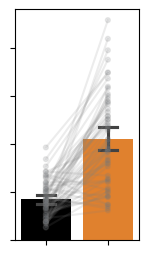

In [27]:
# Create a unique identifier for each pair so Seaborn knows exactly which points to connect
df_analysis_pd["pair_id"] = df_analysis_pd["sid"].astype(str) + "_" + df_analysis_pd["user_id"].astype(str)

print(f"Final Pandas Shape: {df_analysis_pd.shape}")

# 3. Plotting
print("Bootstrapping CIs and plotting...")

# Set up the figure explicitly so we can stack layers on a single axis (ax)
fig, ax = plt.subplots(figsize=(1.6, 3))

# Layer 1: The main bar plot (Averages and CIs)
sns.barplot(
    y="max_corr", 
    x="real_dyad", 
    data=df_analysis_pd, 
    capsize=0.3,
    hue="real_dyad",                
    legend=False,                   
    palette=["#000000", "#FD7F11"],
    alpha=1,            # Slightly transparent so the background bars don't hide the lines
    ax=ax,
    estimator=fisher_mean
)

# Layer 2: Semi-transparent connecting lines
sns.lineplot(
    y="max_corr",
    x="real_dyad",
    data=df_analysis_pd,
    units="pair_id",      # Groups the lines by subject
    estimator=None,       # Stops Seaborn from trying to average the lines together
    color="gray",
    alpha=0.15,            # Makes the lines semi-transparent
    ax=ax
)

# Layer 3: Individual data points
sns.stripplot(
    y="max_corr",
    x="real_dyad",
    data=df_analysis_pd,
    hue="real_dyad",
    palette=["#6D7278", "#6D7278"],
    legend=False,
    size=3.5,
    edgecolor="grey",    # Adds a white border to make the points pop against the lines
    linewidth=1,
    jitter=False,         # CRITICAL: Must be False so the dots perfectly align with the straight lines
    zorder=3,             # Forces the dots to be drawn on top of the bars and lines
    ax=ax,
    alpha=0.15
)

# --- Apply custom axis labels and formatting ---
ax.set_xlabel("Real dyad")
ax.set_ylabel("Max cross-correlation")

# Ensure the ticks align with boolean logic (0=False, 1=True) and force the string format
ax.set_xticks([0, 1])
ax.set_xticklabels(["False", "True"])

#ax.set_ylim(0.1, 0.21)

# plt.title(data_folder)
plt.savefig(f"plots/all_trials_{data_folder}_correlation_plot_legend.pdf", bbox_inches='tight')
ax.set(xticklabels=[], yticklabels=[], title='', xlabel=None, ylabel=None)
plt.savefig(f"plots/all_trials_{data_folder}_correlation_plot.pdf", bbox_inches='tight')
plt.show()

## Comparing aligned and misaligned categories - Data preparation

In [32]:
behavior_df = pl.read_csv("../../data/behavior/all_data_df.csv")

behavior_df = behavior_df.with_columns(
    pl.col("sid").str.replace_all(":", "").alias("sid"),
    pl.col("user_id").str.replace_all(":", "").alias("user_id"),
    pl.col("other_id").str.replace_all(":", "").alias("other_id")
)


In [30]:
# Optimal RAM handling
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
import glob

file_list = glob.glob(f"../../data/hr/{data_folder}/*df_lags.csv")

print(f"Found {len(file_list)} files. Processing in batches...")

agg_dfs = []
batch_size = 5000 # Adjust this up or down depending on your RAM/Speed sweet spot

# 1. Process files in fast, multi-threaded batches
for i in range(0, len(file_list), batch_size):
    batch_files = file_list[i : i + batch_size]
    
    # scan_csv accepts a list of files and parallelizes the read!
    df_batch = (
        pl.scan_csv(batch_files, schema_overrides=df_lags_schema)
        .with_columns([
            pl.col(c).cast(d) for c, d in df_lags_schema.items()
        ])
        .filter(pl.col("analysis").is_in(methods_to_keep))
        # Updated grouping columns
        .group_by(["sid", "dyad", "user_id", "other_id", "real_dyad", "lag", "repetition_nb"]) ##Collapsing across maniplated and analysis
        .agg(
            # Transform to z-score and take the mean
            pl.col("corr") # Select Corr
            .clip(-0.9999, 0.9999) #Clip to perform Fishcher Z transform
            .arctanh() #Fischer Z transform
            .mean() # Mean 
            .alias("z_corr_batch")
            , pl.len().alias("n_rows") # Count rows for the weighted average
        )
        .collect(engine="streaming") 
    )
    agg_dfs.append(df_batch)
    print(f"Processed {min(i + batch_size, len(file_list))} / {len(file_list)} files...")

# 2. Combine the batched results and do one final reduction
print("Combining batches...")
final_pl = (
    pl.concat(agg_dfs)
    # Match the updated grouping columns from Step 1
    .group_by(["sid", "dyad", "user_id", "other_id", "real_dyad", "lag"])
    .agg(
        # Calculate the true weighted average
        (
            (pl.col("z_corr_batch") * pl.col("n_rows")).sum() / pl.col("n_rows").sum()
        ).alias("z_corr_final") 
    )
    .with_columns(
        # Inverse Fisher transform: convert the final z-score back to an r-value
        corr_mean = pl.col("z_corr_final").tanh()
    )
)

df_analysis_pd = final_pl.to_pandas()

print(f"Final Pandas Shape: {df_analysis_pd.shape}")


Found 24440 files. Processing in batches...
Processed 5000 / 24440 files...
Processed 10000 / 24440 files...
Processed 15000 / 24440 files...
Processed 20000 / 24440 files...
Processed 24440 / 24440 files...
Combining batches...
Final Pandas Shape: (14160, 8)


In [33]:
df_analysis = final_pl
merge_df = behavior_df.join(df_analysis, on=["user_id", "sid", "dyad", "other_id"])
merge_df = merge_df.with_columns((pl.col("participant_condition") + pl.col("other_condition")).alias("u_cond"))

In [35]:
merge_df.write_csv("../../data/hr/hr_sync_merge_df.csv")

## Comparing aligned and misaligned categories - Plotting

In [36]:
merge_df = pl.read_csv("../../data/hr/hr_sync_merge_df.csv")

Combining batches...
[UU] Final Pandas Shape: (90, 5)
[SS] Final Pandas Shape: (94, 5)
[US] Final Pandas Shape: (84, 5)


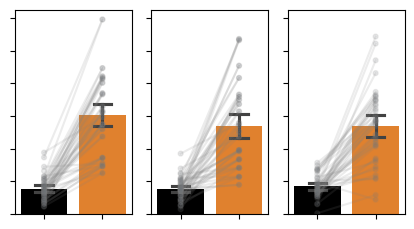

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

print("Combining batches...")

# 1. Group the data and filter out the unwanted condition immediately
grouped_data = [g for g in merge_df.group_by(["u_cond"]) if g[0][0] != "SU"]

# Dynamically set n_plots based on remaining groups
n_plots = len(grouped_data)

# 2. Create the shared figure OUTSIDE the loop
fig, axes = plt.subplots(nrows=1, ncols=n_plots, figsize=(1.6 * n_plots, 3), sharey=True)

# Ensure axes is iterable even if there's only 1 group
if n_plots == 1:
    axes = [axes]

# 3. Loop through the filtered groups
for i, ((u_cond,), df_analysis) in enumerate(grouped_data):
    ax = axes[i]
        
    final_pl = (
        df_analysis
        .filter(pl.col("lag") > -10)
        .filter(pl.col("lag") < 10)
        .group_by(["sid", "user_id", "real_dyad"])
        .agg(pl.col("corr_mean").max()) 
    )

    
    df_analysis_pd = final_pl.to_pandas()
    df_analysis_pd["pair_id"] = df_analysis_pd["sid"].astype(str) + "_" + df_analysis_pd["user_id"].astype(str)
    
    print(f"[{u_cond}] Final Pandas Shape: {df_analysis_pd.shape}")
    
    # Layer 1: The main bar plot (Averages and CIs)
    sns.barplot(
        y="corr_mean", 
        x="real_dyad", 
        data=df_analysis_pd, 
        capsize=0.3,
        hue="real_dyad",                
        legend=False,                  
        palette=["#000000", "#FD7F11"],
        alpha=1,
        ax=ax,
        estimator=fisher_mean
    )
    
    # Layer 2: Semi-transparent connecting lines
    sns.lineplot(
        y="corr_mean",
        x="real_dyad",
        data=df_analysis_pd,
        units="pair_id",      
        estimator=None,       
        color="gray",
        alpha=0.15,            
        ax=ax
    )
    
    # Layer 3: Individual data points
    sns.stripplot(
        y="corr_mean",
        x="real_dyad",
        data=df_analysis_pd,
        hue="real_dyad",
        palette=["#6D7278", "#6D7278"],
        legend=False,
        size=3.5,
        edgecolor="grey",    
        linewidth=1,
        jitter=False,         
        zorder=3,             
        ax=ax,
        alpha=0.15
    )
    
    # --- Apply custom axis labels and formatting ---
    ax.set_xlabel("Real dyad")
    ax.set_title(u_cond)
    
    # Only label the Y-axis on the leftmost plot
    if i == 0:
        ax.set_ylabel("Max cross-correlation")
    else:
        ax.set_ylabel(None)
    
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["False", "True"])
    ax.set_title(u_cond)

# Adjust spacing between subplots
plt.tight_layout()

# Save the combined figure
plt.savefig(f"plots/combined_correlation_plot_legend.pdf", bbox_inches='tight')

# Blank out the text elements for all axes if you need the secondary save
for ax in axes:
    ax.set(xticklabels=[], yticklabels=[], title='', xlabel=None, ylabel=None)

plt.savefig(f"plots/combined_correlation_plot.pdf", bbox_inches='tight')
plt.show()

In [42]:
import scipy.stats as stats
import itertools
import polars as pl
import pandas as pd

print("Aggregating data for statistical analysis...")

# 1. Get the max correlation per session (like your plot does)
# Excluding "SU" to match your plotting logic
df_session = (
    merge_df
    .filter(pl.col("u_cond") != "SU")
    .filter(pl.col("lag") > -10)
    .filter(pl.col("lag") < 10)
    .group_by(["u_cond", "sid", "user_id", "real_dyad"])
    .agg(pl.col("corr_mean").max())
)

# 2. Average per participant to get ONE point per participant, per condition & real_dyad status
df_participant = (
    df_session
    .group_by(["u_cond", "user_id", "real_dyad"])
    .agg(pl.col("corr_mean").mean().alias("avg_corr"))
).to_pandas()

# =====================================================================
# TEST 1: Real vs Fake Dyads (Within each u_cond)
# =====================================================================
print("\n" + "="*60)
print(" PAIRED T-TEST: REAL VS FAKE DYADS (Within Conditions)")
print("="*60)

for cond in df_participant['u_cond'].unique():
    # Filter to current condition and pivot so real_dyad True/False are columns
    df_c = df_participant[df_participant['u_cond'] == cond]
    pivot_c = df_c.pivot(index='user_id', columns='real_dyad', values='avg_corr').dropna()
    
    if len(pivot_c) < 2:
        print(f"Condition: {cond} | Not enough paired data.\n" + "-"*60)
        continue
        
    real_vals = pivot_c[True]
    fake_vals = pivot_c[False]
    
    t_stat, p_val = stats.ttest_rel(real_vals, fake_vals)
    
    print(f"Condition: {cond}")
    print(f"  N (Paired participants) : {len(pivot_c)}")
    print(f"  Real Dyad Mean          : {real_vals.mean():.4f}")
    print(f"  Fake Dyad Mean          : {fake_vals.mean():.4f}")
    print(f"  T-statistic             : {t_stat:.4f}")
    # Using conditional formatting for p-value so it's easy to spot significance
    p_str = f"{p_val:.4f}" + (" *" if p_val < 0.05 else "")
    print(f"  P-value                 : {p_str}")
    print("-" * 60)

# =====================================================================
# TEST 2: Between Conditions (Real vs Real across u_conds)
# =====================================================================
print("\n" + "="*60)
print(" PAIRED T-TEST: BETWEEN CONDITIONS (REAL DYADS ONLY)")
print("="*60)

# Filter to ONLY real dyads
df_real = df_participant[df_participant['real_dyad'] == True]

# Pivot so conditions are columns
pivot_real = df_real.pivot(index='user_id', columns='u_cond', values='avg_corr')
conditions = pivot_real.columns.tolist()

# Test every pair of conditions against each other
for cond1, cond2 in itertools.combinations(conditions, 2):
    # Only keep participants that have real dyad data in BOTH conditions
    pair_df = pivot_real[[cond1, cond2]].dropna()
    
    if len(pair_df) < 2:
        print(f"Comparison: [{cond1}] vs [{cond2}] | Not enough paired data.\n" + "-"*60)
        continue
        
    t_stat, p_val = stats.ttest_rel(pair_df[cond1], pair_df[cond2])
    
    print(f"Comparison: [{cond1}] vs [{cond2}]")
    print(f"  N (Paired participants) : {len(pair_df)}")
    print(f"  {cond1} Mean" + " "*(18-len(cond1)) + f": {pair_df[cond1].mean():.4f}")
    print(f"  {cond2} Mean" + " "*(18-len(cond2)) + f": {pair_df[cond2].mean():.4f}")
    print(f"  T-statistic             : {t_stat:.4f}")
    p_str = f"{p_val:.4f}" + (" *" if p_val < 0.05 else "")
    print(f"  P-value                 : {p_str}")
    print("-" * 60)


# =====================================================================
# TEST 3: Unpaired T-Test Between Conditions (All Data Points)
# =====================================================================
print("\n" + "="*60)
print(" INDEPENDENT T-TEST: BETWEEN CONDITIONS (Per Dyad & Session)")
print("="*60)

# 1. Aggregate to get ONE point per dyad, per session
df_unpaired = (
    merge_df
    .filter(pl.col("u_cond") != "SU")
    .filter(pl.col("lag") > -10)
    .filter(pl.col("lag") < 10)
    .group_by(["u_cond", "sid", "dyad", "real_dyad"])
    .agg(pl.col("corr_mean").max().alias("max_corr"))
).to_pandas()

# Filter to ONLY real dyads (assuming you want to compare actual interactions across conditions)
df_unpaired_real = df_unpaired[df_unpaired['real_dyad'] == True]

conditions = df_unpaired_real['u_cond'].unique()

# Test every pair of conditions against each other
for cond1, cond2 in itertools.combinations(conditions, 2):
    # Extract the flat arrays of data points for each condition
    data1 = df_unpaired_real[df_unpaired_real['u_cond'] == cond1]['max_corr'].dropna()
    data2 = df_unpaired_real[df_unpaired_real['u_cond'] == cond2]['max_corr'].dropna()
    
    if len(data1) == 0 or len(data2) == 0:
        print(f"Comparison: [{cond1}] vs [{cond2}] | Missing data.\n" + "-"*60)
        continue
        
    # Run the independent (unpaired) t-test
    t_stat, p_val = stats.ttest_ind(data1, data2)
    
    print(f"Comparison: [{cond1}] vs [{cond2}] (Unpaired)")
    print(f"  N ({cond1:<4} dyads/sessions) : {len(data1)}")
    print(f"  N ({cond2:<4} dyads/sessions) : {len(data2)}")
    print(f"  {cond1} Mean" + " "*(18-len(cond1)) + f": {data1.mean():.4f}")
    print(f"  {cond2} Mean" + " "*(18-len(cond2)) + f": {data2.mean():.4f}")
    print(f"  T-statistic             : {t_stat:.4f}")
    p_str = f"{p_val:.4f}" + (" *" if p_val < 0.05 else "")
    print(f"  P-value                 : {p_str}")
    print("-" * 60)

Aggregating data for statistical analysis...

 PAIRED T-TEST: REAL VS FAKE DYADS (Within Conditions)
Condition: SS
  N (Paired participants) : 46
  Real Dyad Mean          : 0.0677
  Fake Dyad Mean          : 0.0192
  T-statistic             : 9.7875
  P-value                 : 0.0000 *
------------------------------------------------------------
Condition: UU
  N (Paired participants) : 44
  Real Dyad Mean          : 0.0756
  Fake Dyad Mean          : 0.0192
  T-statistic             : 12.9279
  P-value                 : 0.0000 *
------------------------------------------------------------
Condition: US
  N (Paired participants) : 42
  Real Dyad Mean          : 0.0675
  Fake Dyad Mean          : 0.0211
  T-statistic             : 10.6627
  P-value                 : 0.0000 *
------------------------------------------------------------

 PAIRED T-TEST: BETWEEN CONDITIONS (REAL DYADS ONLY)
Comparison: [SS] vs [US]
  N (Paired participants) : 33
  SS Mean                : 0.0695
  US Mean

In [43]:
import scipy.stats as stats
import itertools
import polars as pl
import pandas as pd

print("Aggregating data for statistical analysis...")

# 1. Get the max correlation per session (like your plot does)
# Excluding "SU" to match your plotting logic
df_session = (
    merge_df
    .filter(pl.col("u_cond") != "SU")
    .filter(pl.col("lag") > -10)
    .filter(pl.col("lag") < 10)
    .group_by(["u_cond", "sid", "user_id", "real_dyad"])
    .agg(pl.col("corr_mean").max())
)

# 2. Average per participant to get ONE point per participant, per condition & real_dyad status
df_participant = (
    df_session
    .group_by(["u_cond", "user_id", "real_dyad"])
    .agg(pl.col("corr_mean").mean().alias("avg_corr"))
).to_pandas()

# =====================================================================
# TEST 1: Real vs Fake Dyads (Within each u_cond)
# =====================================================================
print("\n" + "="*60)
print(" PAIRED T-TEST: REAL VS FAKE DYADS (Within Conditions)")
print("="*60)

for cond in df_participant['u_cond'].unique():
    # Filter to current condition and pivot so real_dyad True/False are columns
    df_c = df_participant[df_participant['u_cond'] == cond]
    pivot_c = df_c.pivot(index='user_id', columns='real_dyad', values='avg_corr').dropna()
    
    if len(pivot_c) < 2:
        print(f"Condition: {cond} | Not enough paired data.\n" + "-"*60)
        continue
        
    real_vals = pivot_c[True]
    fake_vals = pivot_c[False]
    
    t_stat, p_val = stats.ttest_rel(real_vals, fake_vals)
    
    print(f"Condition: {cond}")
    print(f"  N (Paired participants) : {len(pivot_c)}")
    print(f"  Real Dyad Mean          : {real_vals.mean():.4f}")
    print(f"  Fake Dyad Mean          : {fake_vals.mean():.4f}")
    print(f"  T-statistic             : {t_stat:.4f}")
    # Using conditional formatting for p-value so it's easy to spot significance
    p_str = f"{p_val:.4f}" + (" *" if p_val < 0.05 else "")
    print(f"  P-value                 : {p_str}")
    print("-" * 60)

# =====================================================================
# TEST 2: Between Conditions (Real vs Real across u_conds)
# =====================================================================
print("\n" + "="*60)
print(" PAIRED T-TEST: BETWEEN CONDITIONS (REAL DYADS ONLY)")
print("="*60)

# Filter to ONLY real dyads
df_real = df_participant[df_participant['real_dyad'] == True]

# Pivot so conditions are columns
pivot_real = df_real.pivot(index='user_id', columns='u_cond', values='avg_corr')
conditions = pivot_real.columns.tolist()

# Test every pair of conditions against each other
for cond1, cond2 in itertools.combinations(conditions, 2):
    # Only keep participants that have real dyad data in BOTH conditions
    pair_df = pivot_real[[cond1, cond2]].dropna()
    
    if len(pair_df) < 2:
        print(f"Comparison: [{cond1}] vs [{cond2}] | Not enough paired data.\n" + "-"*60)
        continue
        
    t_stat, p_val = stats.ttest_rel(pair_df[cond1], pair_df[cond2])
    
    print(f"Comparison: [{cond1}] vs [{cond2}]")
    print(f"  N (Paired participants) : {len(pair_df)}")
    print(f"  {cond1} Mean" + " "*(18-len(cond1)) + f": {pair_df[cond1].mean():.4f}")
    print(f"  {cond2} Mean" + " "*(18-len(cond2)) + f": {pair_df[cond2].mean():.4f}")
    print(f"  T-statistic             : {t_stat:.4f}")
    p_str = f"{p_val:.4f}" + (" *" if p_val < 0.05 else "")
    print(f"  P-value                 : {p_str}")
    print("-" * 60)


# =====================================================================
# TEST 3: Unpaired T-Test Between Conditions (All Data Points)
# =====================================================================
print("\n" + "="*60)
print(" INDEPENDENT T-TEST: BETWEEN CONDITIONS (Per Dyad & Session)")
print("="*60)

# 1. Aggregate to get ONE point per dyad, per session
df_unpaired = (
    merge_df
    .filter(pl.col("u_cond") != "SU")
    .filter(pl.col("lag") > -10)
    .filter(pl.col("lag") < 10)
    .group_by(["u_cond", "sid", "dyad", "real_dyad"])
    .agg(pl.col("corr_mean").max().alias("max_corr"))
).to_pandas()

# Filter to ONLY real dyads (assuming you want to compare actual interactions across conditions)
df_unpaired_real = df_unpaired[df_unpaired['real_dyad'] == True]

conditions = df_unpaired_real['u_cond'].unique()

# Test every pair of conditions against each other
for cond1, cond2 in itertools.combinations(conditions, 2):
    # Extract the flat arrays of data points for each condition
    data1 = df_unpaired_real[df_unpaired_real['u_cond'] == cond1]['max_corr'].dropna()
    data2 = df_unpaired_real[df_unpaired_real['u_cond'] == cond2]['max_corr'].dropna()
    
    if len(data1) == 0 or len(data2) == 0:
        print(f"Comparison: [{cond1}] vs [{cond2}] | Missing data.\n" + "-"*60)
        continue
        
    # Run the independent (unpaired) t-test
    t_stat, p_val = stats.ttest_ind(data1, data2)
    
    print(f"Comparison: [{cond1}] vs [{cond2}] (Unpaired)")
    print(f"  N ({cond1:<4} dyads/sessions) : {len(data1)}")
    print(f"  N ({cond2:<4} dyads/sessions) : {len(data2)}")
    print(f"  {cond1} Mean" + " "*(18-len(cond1)) + f": {data1.mean():.4f}")
    print(f"  {cond2} Mean" + " "*(18-len(cond2)) + f": {data2.mean():.4f}")
    print(f"  T-statistic             : {t_stat:.4f}")
    p_str = f"{p_val:.4f}" + (" *" if p_val < 0.05 else "")
    print(f"  P-value                 : {p_str}")
    print("-" * 60)

Aggregating data for statistical analysis...

 PAIRED T-TEST: REAL VS FAKE DYADS (Within Conditions)
Condition: SS
  N (Paired participants) : 46
  Real Dyad Mean          : 0.0677
  Fake Dyad Mean          : 0.0192
  T-statistic             : 9.7875
  P-value                 : 0.0000 *
------------------------------------------------------------
Condition: UU
  N (Paired participants) : 44
  Real Dyad Mean          : 0.0756
  Fake Dyad Mean          : 0.0192
  T-statistic             : 12.9279
  P-value                 : 0.0000 *
------------------------------------------------------------
Condition: US
  N (Paired participants) : 42
  Real Dyad Mean          : 0.0675
  Fake Dyad Mean          : 0.0211
  T-statistic             : 10.6627
  P-value                 : 0.0000 *
------------------------------------------------------------

 PAIRED T-TEST: BETWEEN CONDITIONS (REAL DYADS ONLY)
Comparison: [SS] vs [US]
  N (Paired participants) : 33
  SS Mean                : 0.0695
  US Mean